<a href="https://colab.research.google.com/github/mmkinfo25-prog/python/blob/main/Logistic_reg_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
   Student_ID  Study_Hours  Attendance_Percent  Previous_Marks  \
0        1001          1.0                  65              38   
1        1002          2.0                  70              42   
2        1003          3.0                  72              48   
3        1004          4.0                  75              50   
4        1005          5.0                  78              55   

   Assignment_Score  Exam_Marks Result  
0                40          35   fail  
1                45          40   fail  
2                50          46   fail  
3                55          52   pass  
4                58          57   pass  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_ID          30 non-null     int64  
 1   Study_Hours         30 non-null     float64
 2   Attendance_Percent  30 

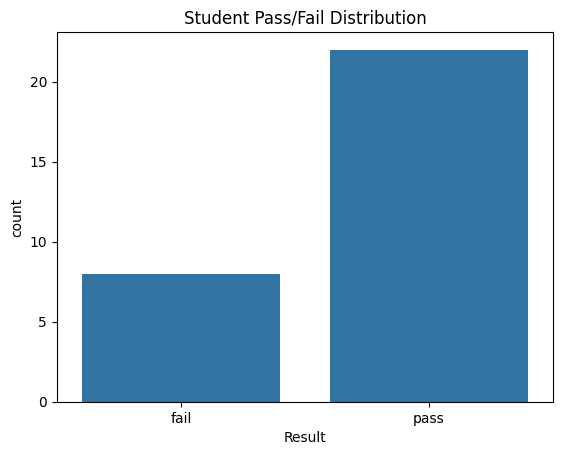

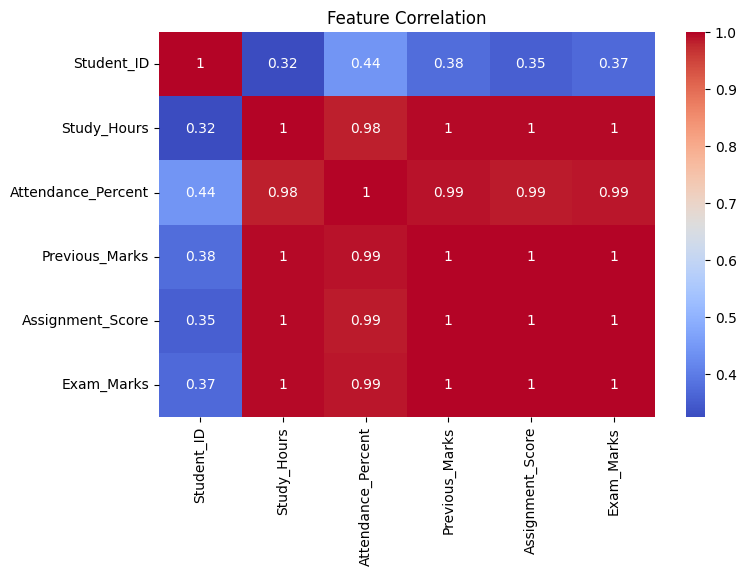


Class Mapping:
{'fail': np.int64(0), 'pass': np.int64(1)}

Training Records: 24
Testing Records: 6

Logistic Regression Model Trained Successfully!

========== MODEL PERFORMANCE ==========
Accuracy  : 100.0 %
Precision : 1.0
Recall    : 1.0
F1 Score  : 1.0
ROC-AUC   : 1.0

Classification Report:
              precision    recall  f1-score   support

        fail       1.00      1.00      1.00         2
        pass       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



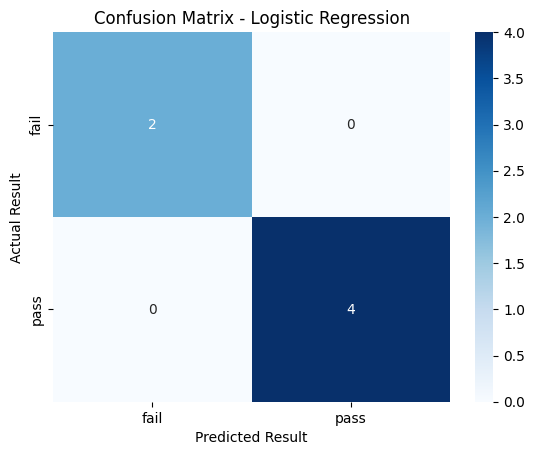


Actual vs Predicted Results:
  Actual_Result Predicted_Result
0          fail             fail
1          pass             pass
2          pass             pass
3          pass             pass
4          fail             fail
5          pass             pass

========== NEW STUDENT PREDICTION ==========
Predicted Result: pass
Fail Probability: 0.15 %
Pass Probability: 99.85 %

Feature Coefficients:
              Feature  Coefficient
0         Study_Hours     0.791282
4          Exam_Marks     0.758451
3    Assignment_Score     0.744989
2      Previous_Marks     0.716042
1  Attendance_Percent     0.679348


In [1]:

# ==========================================================
# STUDENT RESULT PREDICTION USING LOGISTIC REGRESSION
# ==========================================================

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Step 2: Load Dataset

df = pd.read_excel("/Linear_Regression_FDP_Student_Dataset.xlsx")

print("Dataset:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nResult Distribution:")
print(df['Result'].value_counts())


# Step 3: Exploratory Data Analysis

sns.countplot(data=df, x='Result')
plt.title("Student Pass/Fail Distribution")
plt.show()

# Correlation among numerical features
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Feature Correlation")
plt.show()


# Step 4: Select Input and Output

# Student_ID is excluded because it is an identifier.

X = df[
    [
        'Study_Hours',
        'Attendance_Percent',
        'Previous_Marks',
        'Assignment_Score',
        'Exam_Marks'
    ]
]

y = df['Result']

# Convert Pass/Fail into 1/0
le = LabelEncoder()
y = le.fit_transform(y)

print("\nClass Mapping:")
print(dict(zip(le.classes_, le.transform(le.classes_))))


# Step 5: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


# Step 6: Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Step 7: Build Logistic Regression Model

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("\nLogistic Regression Model Trained Successfully!")


# Step 8: Predict Test Results

y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:, 1]


# Step 9: Performance Evaluation

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_prob)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision, 3))
print("Recall    :", round(recall, 3))
print("F1 Score  :", round(f1, 3))
print("ROC-AUC   :", round(roc_auc, 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_,
    zero_division=0
))


# Step 10: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


# Step 11: Actual vs Predicted Results

results = pd.DataFrame({
    'Actual_Result': le.inverse_transform(y_test),
    'Predicted_Result': le.inverse_transform(y_pred)
})

print("\nActual vs Predicted Results:")
print(results)


# Step 12: Predict New Student Result

new_student = pd.DataFrame([{
    'Study_Hours': 6,
    'Attendance_Percent': 85,
    'Previous_Marks': 70,
    'Assignment_Score': 80,
    'Exam_Marks': 75
}])

new_student_scaled = scaler.transform(new_student)

prediction = model.predict(new_student_scaled)

probability = model.predict_proba(new_student_scaled)

print("\n========== NEW STUDENT PREDICTION ==========")

print("Predicted Result:", le.inverse_transform(prediction)[0])

print("Fail Probability:", round(probability[0][0] * 100, 2), "%")
print("Pass Probability:", round(probability[0][1] * 100, 2), "%")


# Step 13: Feature Importance (Model Coefficients)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print("\nFeature Coefficients:")
print(importance.sort_values(
    by='Coefficient',
    ascending=False
))
